In [69]:
'''
Predict the price of the Uber ride from a given pickup point to the agreed drop-off location.
Perform following tasks:
1. Pre-process the dataset.
2. Identify outliers.
3. Check the correlation.
4. Implement linear regression and random forest regression models.
5. Evaluate the models and compare their respective scores like R2, RMSE,
'''


import pandas as pd
!pip install matplotlib
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [70]:
# !pip3 install scikit-learn

In [71]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

In [72]:
df = pd.read_csv("uber.csv")

In [73]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [74]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  str    
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  str    
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), str(2)
memory usage: 13.7 MB
None


In [75]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64


In [76]:
df = df.dropna()

In [77]:
print(df.isnull().sum())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64


In [78]:
# calculate distance using Euclidean formula
df["distance"] = (
    ((df["dropoff_latitude"] - df["pickup_latitude"])**2 +
                  (df["dropoff_longitude"] - df["pickup_longitude"]) **2) * 0.5
)

In [79]:
df["distance"]

0         1.146067e-04
1         2.442680e-04
2         1.410262e-03
3         1.365939e-04
4         1.302101e-03
              ...     
199995    5.660945e-07
199996    2.447738e-04
199997    1.011366e-02
199998    5.478301e-04
199999    1.187244e-03
Name: distance, Length: 199999, dtype: float64

In [80]:
# calculate fare, passenger count and distance

df = df[(df["fare_amount"] > 0) & (df["fare_amount"] < 100)]
df = df[(df["passenger_count"] > 0) & (df["passenger_count"] <= 6)]
df = df[df["distance"] < 5]

In [81]:
df

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,1.146067e-04
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,2.442680e-04
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,1.410262e-03
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,1.365939e-04
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,1.302101e-03
...,...,...,...,...,...,...,...,...,...,...
199995,42598914,2012-10-28 10:49:00.00000053,3.0,2012-10-28 10:49:00 UTC,-73.987042,40.739367,-73.986525,40.740297,1,5.660945e-07
199996,16382965,2014-03-14 01:09:00.0000008,7.5,2014-03-14 01:09:00 UTC,-73.984722,40.736837,-74.006672,40.739620,1,2.447738e-04
199997,27804658,2009-06-29 00:42:00.00000078,30.9,2009-06-29 00:42:00 UTC,-73.986017,40.756487,-73.858957,40.692588,2,1.011366e-02
199998,20259894,2015-05-20 14:56:25.0000004,14.5,2015-05-20 14:56:25 UTC,-73.997124,40.725452,-73.983215,40.695415,1,5.478301e-04


In [82]:
# extract time features
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

In [83]:
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df['pickup_datetime'].dt.dayofweek

/var/folders/9m/_ttwl34j6lq4ly39g6gsgwnw0000gn/T/ipykernel_4853/4196340217.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df['day_of_week'] = df['pickup_datetime'].dt.dayofweek


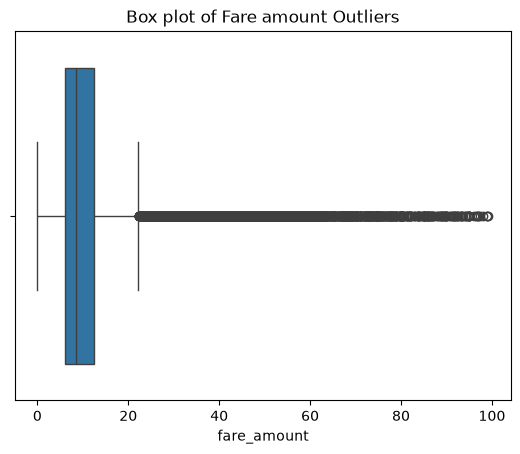

In [84]:
sns.boxplot(x = df['fare_amount'])
plt.title("Box plot of Fare amount Outliers")
plt.show()

In [85]:
#corelation heatmap
corr = df[['fare_amount', 'distance', 'passenger_count', 'hour', 'day_of_week']]. corr()

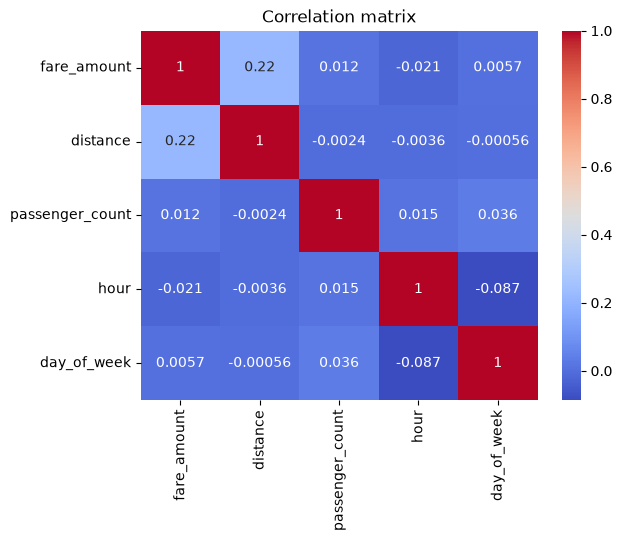

In [86]:
sns.heatmap(corr, annot = True, cmap = 'coolwarm')
plt.title("Correlation matrix")
plt.show()

In [87]:
X = df[['distance', 'passenger_count', 'hour', 'day_of_week']]
Y = df['fare_amount']

#train
X_train, X_test, Y_train, Y_test = train_test_split(
    X,Y, test_size=0.2, random_state=42
)

#linear regression

lr = LinearRegression()
lr.fit(X_train, Y_train)

Y_pred = lr.predict(X_test)